# Setup

In [1]:
import sys
sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

from pathlib import Path
import pickle,gzip,math,os,time,shutil,torch,random,logging
import fastcore.all as fc,matplotlib as mpl,numpy as np,matplotlib.pyplot as plt
from collections.abc import Mapping
from pathlib import Path
from functools import partial

from fastcore.foundation import L
import torchvision.transforms.functional as TF,torch.nn.functional as F
from torch import tensor,nn,optim
from torch.utils.data import DataLoader,default_collate
from torch.nn import init
from torch.optim import lr_scheduler

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *

from torcheval.metrics import MulticlassAccuracy
from datasets import load_dataset,load_dataset_builder

mpl.rcParams['image.cmap'] = 'gray_r'
logging.disable(logging.WARNING)

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


In [2]:
xl,yl = 'image','label'
name = "fashion_mnist"
dsd = load_dataset(name)

@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2)) for o in b[xl]]

bs = 128
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=8)

    this transform:
    F.pad(TF.to_tensor(o), (2,2,2,2))
    → pixels in [0, 1]  ← no *2-1
    → adds 2 pixels on each side
    → 28×28 becomes 32×32

    (2,2,2,2) = (left, right, top, bottom)
    pads with zeros (black pixels) ✓

    WHY 32×32:
    ─────────────────────────────────────────
    U-Net does multiple halvings internally
    32 → 16 → 8 → 4  ← clean halvings ✓
    28 → 14 → 7 → 3.5 ← breaks at odd numbers ✗


In [3]:
dt = dls.train
xb,yb = next(iter(dt))

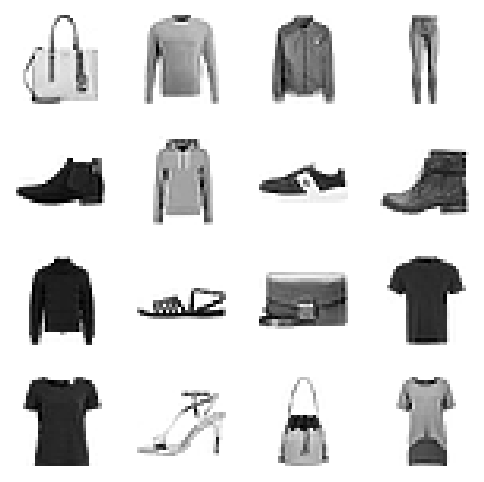

In [4]:
show_images(xb[:16], imsize=1.5)

# Noising and Variables

    N(xt ; √(1-βt) × x(t-1) , βt × I)
    ↑
    N = Normal distribution (Gaussian)
    -----------------------------------------
    N(mean, variance)
         ↑       ↑
         √(1-βt) × x(t-1)    βt × I
         ↑                    ↑
         mean of              variance of
         the distribution     the distribution
    -------------------------------------------
    given we know x(t-1)
    the next step xt is drawn from
    a normal distribution
    centered at √(1-βt) × x(t-1)
    with noise amount βt ✓

In [5]:
beta_min, beta_max, n_steps = 0.0001,0.02,1000
beta = torch.linspace(beta_min, beta_max, n_steps)
alpha = 1.-beta # alpha? -> just a rename to write less
alphabar = alpha.cumprod(dim=0)
sigma = beta.sqrt()  # sigma? -> just a rename to write less

    WHY ALPHABAR:
    ─────────────────────────────────────────
    training needs noisy image at random t=455
    running 455 steps is too slow
    alphabar = factorial-style shortcut
    ᾱ[455] = (1-β1)×(1-β2)×...×(1-β455)
    x455 = √ᾱ[455] × x0 + √(1-ᾱ[455]) × ε
    one line, instant ✓

    WHY ALPHA IN ALPHABAR NOT BETA:
    ─────────────────────────────────────────
    (1-β1)×(1-β2)×...×(1-β455)
    = image survival × survival × survival...
    = total image remaining ✓

    if we used β:
    β1×β2×...×β455 = noise×noise×noise
    = meaningless ✗

    WHY (1-β) NOT β:
    ─────────────────────────────────────────
    β + (1-β) = 1    always, no matter what β is
    ↑      ↑
    noise  image
    share  share

    β=0.02 means: MAXIMUM β in our case
      2%  noise  (β)
      98% image  (1-β)
      always sums to 100% ✓

    how MAXIMUM β is 2% noise and make the image pure noise
    -> β -> per step, after 1000 steps it accumulates  pure noise

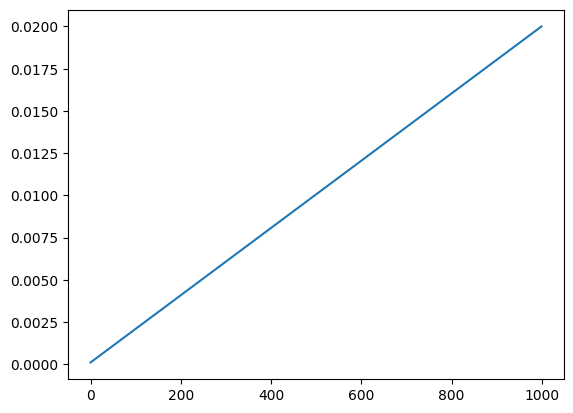

In [6]:
plt.plot(beta);

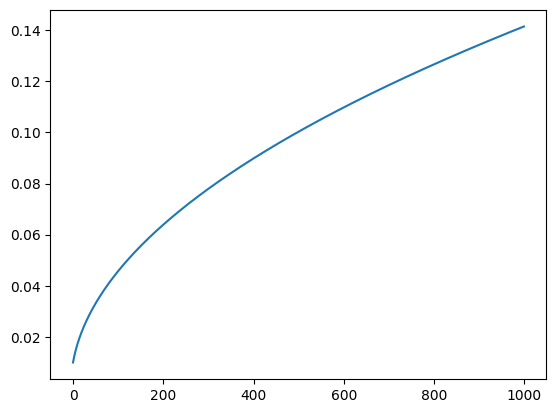

In [7]:
plt.plot(sigma);

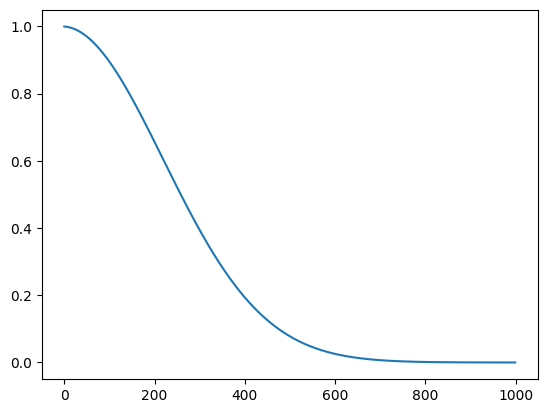

In [8]:
plt.plot(alphabar);

In [9]:
alphabar[5]

tensor(0.9991)

In [10]:
def noisify(x0,ab,n_steps=1000): # ab is alphabar
    device = x0.device
    n = len(x0)
    t = torch.randint(0,n_steps,(n,),dtype=torch.long)
    eps = torch.randn(x0.shape,device=device)
    ab_t = ab[t].reshape(-1,1,1,1).to(device) # adds 3 dims so it can broadcast with image
    x_t = ab_t.sqrt() * x0 + (1-ab_t).sqrt() * eps
    return (x_t , t.to(device)) , eps

at `t = torch.randint(0,n_steps,(n,),dtype=torch.long)`:

- ` torch.long` -> make clean int eg.7
- `torch.randint` -> needs a TUPLE for shape , else it can make error or give wrong number

 - (2,4) → `reshape(-1,1,1,1)` → (8,1,1,1) [ -1 -> leave torch to figure it out ]

In [11]:
(xt,t),eps = noisify(xb[:25],alphabar)
t

tensor([781, 789, 367, 620, 374, 199, 554, 721, 746, 990, 381, 479,  64, 181,
        160, 117, 754, 978, 799, 188, 486,  22, 362, 140, 235])

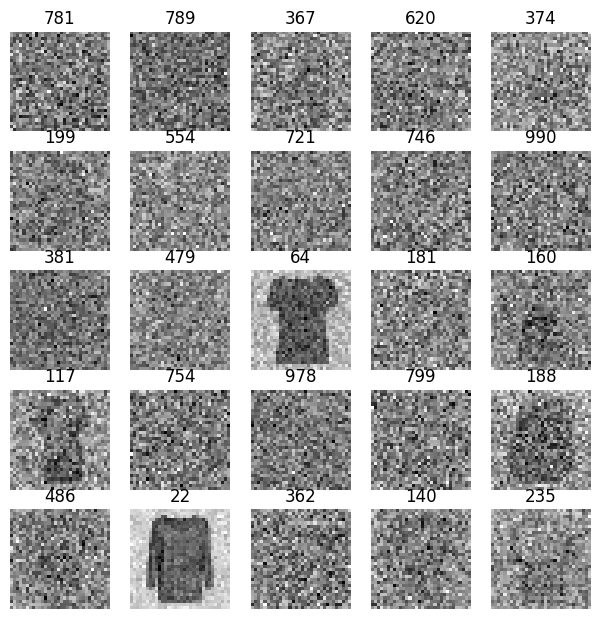

In [12]:
titles = fc.map_ex(t, '{}') # just mapping all t(s) to strings
show_images(xt, imsize=1.5, titles=titles)

# Training

In [13]:
# use a HF one for now
from diffusers import UNet2DModel

In [14]:
@torch.no_grad()
def sample (model, sz, a  , sigma , n_steps , ab=alphabar):
    device = next(model.parameters()).device
    x_t = torch.randn(sz, device = device) # we start with pure random noise
    preds = []
    for t in reversed(range(n_steps)):
        t_batch = torch.full((x_t.shape[0],), t, device=device, dtype=torch.long)
        z = (torch.randn(x_t.shape) if t>0 else torch.zeros(x_t.shape)).to(device)
        ab_t1 = ab[t-1] if t>0 else torch.tensor(1)
        bb_t = 1 - ab[t]
        bb_t1 = 1 - ab_t1
        x_0_hat = ((x_t - bb_t.sqrt() * learn.model((x_t, t_batch)))/alphabar[t].sqrt()).clamp(-1,1)
        x_t = x_0_hat * ab_t1.sqrt()*(1-alpha[t])/bb_t  +  x_t * alpha[t].sqrt()*bb_t1/bb_t + sigma[t] * z
        preds.append(x_t.cpu())
    return preds

- `t_batch` -> tensor of same t for all images in batch (bs,)
- `z` -> added noise at the end
- `bb` -> is betabar is just short for (1-ab)
- `x_0_hat` -> "hat" means the predicted version of something

for `x_0_hat` calc:
- -> rearranging: `xt = √ᾱt × x0 + √(1-ᾱt) × ε `
- solve for x0: `x0_hat = (xt - √(1-ᾱt) × ε_predicted) / √ᾱt`
- `.clamp(-1, 1):`keep pixel values in valid range ->  prevents extreme values ✓

    FOR `x_t` calc, what is needed to be understood:

    x(t-1) = weight1 × x0_hat
            + weight2 × xt
            + noise

    the coeffs came from deriving the reverse distribution mathematically
    → not intuitive

    WHY SQUARE ROOTS EVERYWHERE? (for scaling):
    β is defined as VARIANCE -> to use as a coefficient you need STD not variance

`@torch.no_grad()` -> every time you call sample() it automatically , runs inside no_grad ✓

`torch.full((2, 3), 3.141592)`:

    -> tensor([[ 3.1416,  3.1416,  3.1416],
               [ 3.1416,  3.1416,  3.1416]])

In [15]:
class DDPMCB(Callback):
    order = DeviceCB.order+1
    def __init__(self,n_steps,beta_min,beta_max):
        super().__init__()
        fc.store_attr()
        self.beta = torch.linspace(self.beta_min,self.beta_max,self.n_steps)
        self.alpha = 1.- self.beta
        self.alphabar =  self.alpha.cumprod(dim=0)
        self.sigma = self.beta.sqrt()
    def before_batch(self,learner): learn.batch = noisify(learn.batch[0],self.alphabar,self.n_steps)
    def sample(self,model,sz): return sample(model,sz,self.alpha,self.sigma,self.n_steps,self.alphabar)

In [16]:
class UNet(UNet2DModel):
    def forward(self, x): return super().forward(*x).sample

model takes 2 things `x_t` , `t` , so we unpack it , and HF stores the results in sample object so we get it

In [17]:
ddpm_cb = DDPMCB(n_steps=1000, beta_min=0.0001, beta_max=0.02)

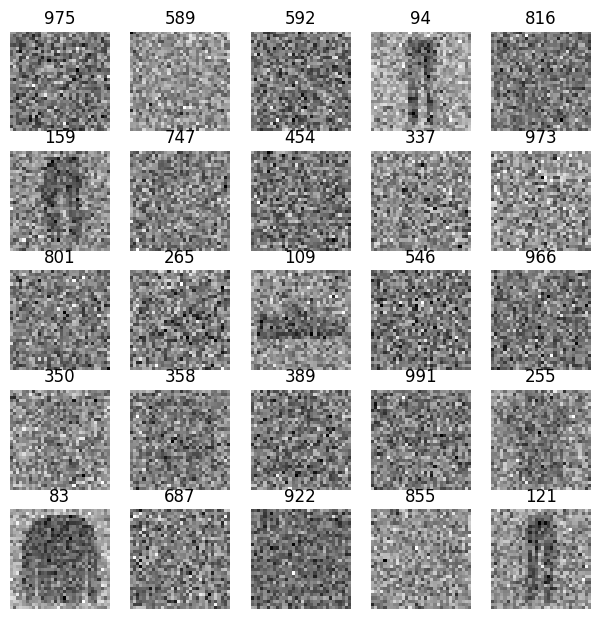

In [18]:
model = UNet(in_channels=1, out_channels=1, block_out_channels=(16, 32, 64, 64), norm_num_groups=8)
# take a look at the batchs inside the model
learn = TrainLearner(model, dls, nn.MSELoss())
learn.fit(train=False, cbs=[ddpm_cb,SingleBatchCB()])
(xt,t),ε = learn.batch
show_images(xt[:25], titles=fc.map_ex(t[:25], '{}'), imsize=1.5)

    input: (1024, 16, 28, 28)
    BatchNorm:  mean (1,  16, 1,  1 ) broadcasts over (1024, 16, 28, 28)
    LayerNorm:  mean (1024, 1, 1,  1 ) broadcasts over (1024, 16, 28, 28)
    GroupNorm:  mean (1024, 8, 1,  1 ) broadcasts over (1024, 8, 2, 28, 28)

    GROUPNORM — HOW IT ACTUALLY COMPUTES:
    ─────────────────────────────────────────
    STEP 1: reshape to expose groups
    (1024, 16, 28, 28) → (1024, 8, 2, 28, 28)
             ↑                   ↑  ↑
           channels           groups  channels per group

    STEP 2: compute mean+std over the LAST 3 dims (2, 28, 28)
    result shape: (1024, 8, 1, 1, 1)
                  ↑      ↑
               each    each
               image   group
               has     has
               its     its
               own     own

    STEP 3: subtract and divide → broadcasts automatically
    (1024, 8, 2, 28, 28) - (1024, 8, 1, 1, 1)
                             ↑
                        pytorch broadcasts 1,1,1 → 2,28,28 ✓

    STEP 4: reshape back
    (1024, 8, 2, 28, 28) → (1024, 16, 28, 28) ✓


In [19]:
model = UNet(in_channels=1, out_channels=1, block_out_channels=(16, 32, 64, 128), norm_num_groups=8)

In [20]:
def init_ddpm(model):
    for o in model.down_blocks:
        for p in o.resnets:
            p.conv2.weight.data.zero_()
            for p in fc.L(o.downsamplers): init.orthogonal_(p.conv.weight)

    for o in model.up_blocks:
        for p in o.resnets: p.conv2.weight.data.zero_()

    model.conv_out.weight.data.zero_()

this is just for initializing the weights , we just go in the resnet blocks and make the second conv weights = 0 , so that at the beggining the value that comes from the resnet is the identity + some orthogonal init thing , then... (we have seen it before)

In [21]:
lr = 5e-3
epochs = 5
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [ddpm_cb, DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched)]
init_ddpm(model)
opt_func = partial(optim.Adam, eps=1e-5)
learn = TrainLearner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

loss,epoch,train
0.148,0,train
0.032,0,eval
0.023,1,train
0.022,1,eval
0.021,2,train
0.019,2,eval
0.019,3,train
0.019,3,eval
0.018,4,train
0.019,4,eval


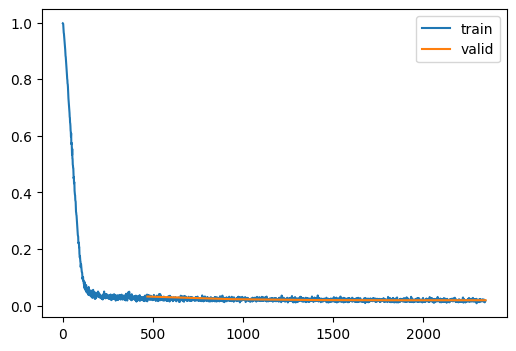

In [22]:
learn.fit(epochs)

# Sampling

In [23]:
samples = ddpm_cb.sample(learn.model,(16,1,32,32))

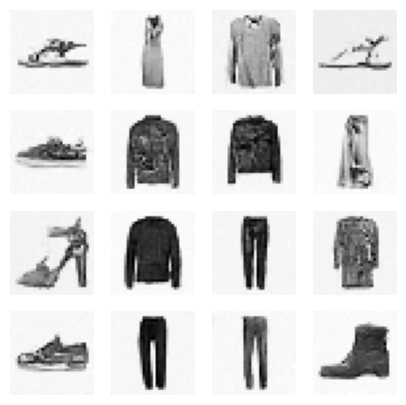

In [24]:
show_images(samples[-1], figsize=(5,5))

In [25]:
%matplotlib inline
import matplotlib.animation as animation
from IPython.display import display, HTML

fig,ax = plt.subplots(figsize=(3,3))
def _show_i(i): return show_image(samples[i][0], ax=ax, animated=True).get_images()
r = L.range(800,990, 5)+L.range(990,1000)+[999]*10
ims = r.map(_show_i)

animate = animation.ArtistAnimation(fig, ims, interval=50, blit=True, repeat_delay=3000)
plt.close(fig)
display(HTML(animate.to_jshtml()))

Note that I only take the steps between 800 and 1000 since most of the previous steps are actually quite noisy. This is a limitation of the noise schedule used for small images, and papers like [Improved DDPM](https://arxiv.org/abs/2102.09672) suggest other noise schedules for this purpose! (Some potential homework: try out the noise schedule from Improved DDPM and see if it helps.)

# Mixed Percision
(make the computations faster)

In [26]:
next(iter(DataLoader(tds['train'], batch_size=2)))

{'image': tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]],
 
 
         [[[0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           ...,
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.],
           [0., 0., 0.,  ..., 0., 0., 0.]]]]),
 'label': tensor([9, 0])}

here we can make the noisifying there in the collate function

In [27]:
def collate_ddpm(b): return noisify(default_collate(b)[xl],alphabar)
def dl_ddpm(ds): return DataLoader(ds,batch_size=bs,collate_fn=collate_ddpm,num_workers=4)

In [28]:
dls = DataLoaders(dl_ddpm(tds['train']),dl_ddpm(tds['test']))

 this is our DL class just makes use dls.train and dls.test

In [29]:
class MixedPrecision(TrainCB):
    order = DeviceCB.order+10 # +10 is to leave room for other callback between this 2 CBs
    def before_fit(self,learn): self.scaler = torch.cuda.amp.GradScaler()
    def before_batch(self,learn):
        self.autocast = torch.autocast("cuda", dtype=torch.float16)
        self.autocast.__enter__()
    def after_loss(self, learn): self.autocast.__exit__(None, None, None)
    def backward(self, learn): self.scaler.scale(learn.loss).backward()
    def step(self, learn):
        self.scaler.step(learn.opt)
        self.scaler.update()

this is just making the steps that are in the torch documentations

    with = just calls __enter__ at start
           and __exit__ at end automatically

    with autocast at class:    →    autocast.__enter__()
        we made it as               do stuff
                                    autocast.__exit__(None,None,None)

    we made it like this to avoid rewriting the fit and use the callbacks
    functionality that we made

In [30]:
bs = 256 # just to make the gpu full so that the mixed precision makes a diff
lr = 1e-2 # make lr bigger because of the bigger batch (less updates)
epochs = 8 # same reason as the lr
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), MixedPrecision(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched)]
model = UNet(in_channels=1, out_channels=1, block_out_channels=(16, 32, 64, 128), norm_num_groups=8)
init_ddpm(model)
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

/tmp/ipykernel_88224/3423123861.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self,learn): self.scaler = torch.cuda.amp.GradScaler()


loss,epoch,train
0.104,0,train
0.025,0,eval
0.024,1,train
0.022,1,eval
0.022,2,train
0.020,2,eval
0.020,3,train
0.020,3,eval
0.019,4,train
0.019,4,eval


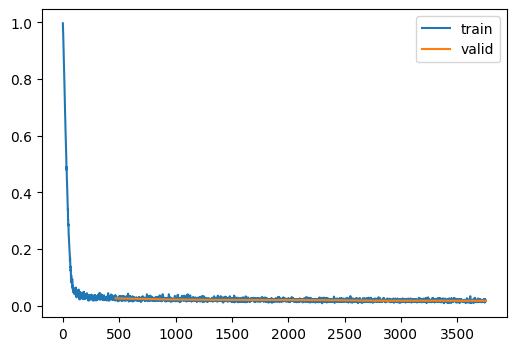

In [31]:
learn.fit(epochs)

In [36]:
samples = sample(learn.model, (32, 1, 32, 32), alpha,sigma, n_steps,alphabar)

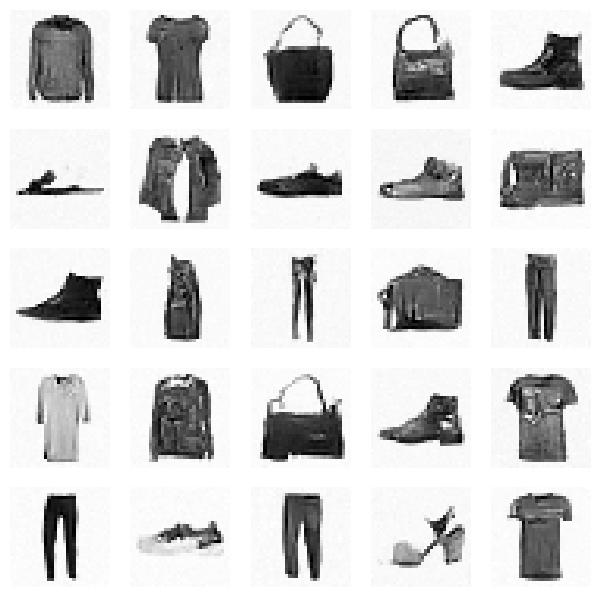

In [37]:
show_images(samples[-1][:25], imsize=1.5)

# Accelerate
that is a library that can automate the :
- Mixed precision
- MULTI-GPU / Distributed training
- Make the same code run on  GPU , TPU , CPU ,etc..

In [38]:
from accelerate import Accelerator

In [44]:
class AccelerateCB(TrainCB):
    order = DeviceCB.order+10  ## +10 is to leave room for other callback between this 2 CBs
    def __init__(self,n_inp=1,mixed_precision='fp16'):
        super().__init__(n_inp=n_inp)
        self.acc = Accelerator(mixed_precision=mixed_precision)
    def before_fit(self,learn): # wrap (model,opt,data) in acc
        learn.model,learn.opt,learn.dls.train,learn.dls.valid = self.acc.prepare(
            learn.model, learn.opt, learn.dls.train, learn.dls.valid)
    def backward(self,learn): self.acc.backward(learn.loss)

In [45]:
def noisify(x0,ab,n_steps=1000):
    device = x0.device
    n = len(x0)
    t = torch.randint(0,n_steps,(n,),dtype=torch.long)
    eps = torch.randn(x0.shape,device=device)
    ab_t = ab[t].reshape(-1,1,1,1).to(device)
    x_t = ab_t.sqrt() * x0 + (1-ab_t).sqrt() * eps
    return x_t , t.to(device) , eps # <- change here

- difference here is that we here return all of the 3 things in same tuple not ((...),eps) as before
- becuase we will when we make an instance of the AccelerateCB we will pass the `n_inp = 2` , so the model is going to have `*noisify()[:n_inp]` as the input and the labels is going to be `*noisify()[n_inp:]`

In [46]:
class DDPMCB2(Callback):
    def after_predict(self,learn): learn.preds = learn.preds.sample

- here we get the `preds` out of the `.sample` object that HF makes

In [47]:
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test'])) # rerun same thing again

In [48]:
model = UNet2DModel(in_channels=1, out_channels=1, block_out_channels=(16, 32, 64, 128), norm_num_groups=8)
init_ddpm(model)
cbs = [DDPMCB2(), DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), AccelerateCB(n_inp=2)]
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

loss,epoch,train
0.178,0,train
0.029,0,eval
0.025,1,train
0.025,1,eval
0.023,2,train
0.025,2,eval
0.022,3,train
0.021,3,eval
0.021,4,train
0.020,4,eval


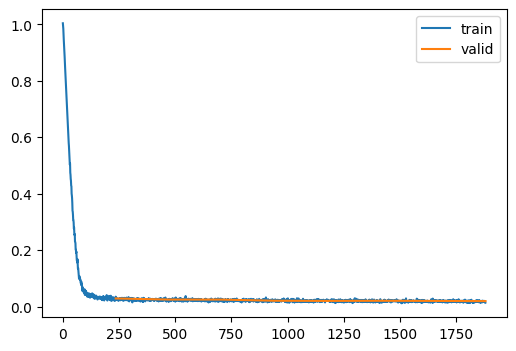

In [49]:
learn.fit(epochs)

In [ ]:
mdl_path = Path('../models/fashion_ddpm_mp.pkl')
if not mdl_path.exists(): torch.save(learn.model, mdl_path)

# A Trick for slow CPUs

In [52]:
class MultDL:
    def __init__(self,dl,mult=2): self.dl,self.mult = dl,mult
    def __len__(self): return len(self.dl)*self.mult
    def __iter__(self):
        for b in self.dl:
            for i in range(self.mult): yield b

    NORMAL dl:          batch1 → batch2 → batch3 → batch4
                          ↑         ↑         ↑         ↑
                       load      load      load      load   (CPU slow)

    MultDL(mult=2):   batch1 → batch1 → batch2 → batch2
                        ↑         ↑         ↑         ↑
                      load      FREE     load       FREE   (reuse!) ✓

    outer loop gets batch1
        inner loop i=0 → yield batch1  ← caller gets batch1, PAUSES here
        inner loop i=1 → yield batch1  ← caller gets batch1 again, PAUSES
    outer loop gets batch2
        inner loop i=0 → yield batch2
        inner loop i=1 → yield batch2
    ...

    return:             runs function → gives value → function DIES
                        next call → starts from beginning

    yield (The key):    runs function → gives value → function FREEZES
                        next call → CONTINUES from where it froze ✓

In [53]:
dls.train = MultDL(dls.train) # an example